In [3]:
# Check files in current working directory and verify plant and bus features filenames
import os

print("Files in current directory:", os.listdir())

Files in current directory: ['Untitled spreadsheet - PLNT23.csv', 'usa_bus_features_2016.csv', 'siting_with_transmission.ipynb', 'TRANSMISSION_DATA_SUMMARY.md', '.DS_Store', 'LICENSE', 'requirements.txt', 'GRANULARITY_SUMMARY.md', 'README.md', 'DATAPLACE_README.md', 'meta_datacenter_top20_with_transmission_20251115_1751.csv', 'COMPREHENSIVE_MODEL_SUMMARY.md', 'app.py', 'STATE_CODE_EXPLANATION.md', 'algo.ipynb', '.git', 'all_substations_scored_20251115_1751.csv', 'MAP_VISUALIZATION_GUIDE.md', 'data']


In [4]:
# Load the power plants file, dropping the duplicate header row per prior insight
import pandas as pd

# Load PLNT23, skip the duplicate header row
plants_path = 'Untitled spreadsheet - PLNT23.csv'
df_plants = pd.read_csv(plants_path)
df_plants = df_plants.iloc[1:]  # Drop the duplicate header row

# Load bus features
df_buses = pd.read_csv('usa_bus_features_2016.csv')

# Check the first few rows, columns, and info for both
display(df_plants.head(3))
print('PLNT23 columns:', df_plants.columns.tolist()[:10], '...')
display(df_buses.head(3))
print('Buses columns:', df_buses.columns.tolist()[:10], '...')

# Show info for identifying empty or object columns
df_buses.info()

/var/folders/4c/rg1h67_11_n4pg2t3_swv4h00000gn/T/ipykernel_61423/3450093176.py:6: DtypeWarning: Columns (0,1,4,6,8,16,17,19,20,22,23,27,29,33,34,35,50,51,52,53,55,56,58,59,60,61,62,63,64,65,66,67,68,69,71,72,74,82,85,86,97,98,99,102,107,122) have mixed types. Specify dtype option on import or set low_memory=False.
  df_plants = pd.read_csv(plants_path)


,Plant file sequence number,Data Year,Plant state abbreviation,Plant name,DOE/EIA ORIS plant or facility code,Plant transmission or distribution system owner name,Plant transmission or distribution system owner ID,Utility name,Utility ID,Plant-level sector,...,Plant geothermal generation percent (resource mix),Plant other fossil generation percent (resource mix),Plant other unknown / purchased fuel generation percent (resource mix),Plant total nonrenewables generation percent (resource mix),Plant total renewables generation percent (resource mix),Plant total nonrenewables other unknown/purchased generation percent (resource mix),Plant total nonhydro renewables generation percent (resource mix),Plant total combustion generation percent (resource mix),Plant total noncombustion generation percent (resource mix),Plant total noncombustion other unknown/purchased generation percent (resource mix)
1,1,2023,AK,Alakanuk,57053,"Alaska Village Elec Coop, Inc",221,"Alaska Village Elec Coop, Inc",221,Electric Utility,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2023,AK,Allison Creek Hydro,58982,"Copper Valley Elec Assn, Inc",4329,"Copper Valley Elec Assn, Inc",4329,Electric Utility,...,0.0%,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%,0.0%,100.0%,0.0%
3,3,2023,AK,Ambler,60243,"Alaska Village Elec Coop, Inc",221,"Alaska Village Elec Coop, Inc",221,Electric Utility,...,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%


PLNT23 columns: ['Plant file sequence number', 'Data Year', 'Plant state abbreviation', 'Plant name', 'DOE/EIA ORIS plant or facility code', 'Plant transmission or distribution system owner name', 'Plant transmission or distribution system owner ID', 'Utility name', 'Utility ID', 'Plant-level sector'] ...


,bus_id,node_lat,node_lon,interconnect_id,zone_name,state_code,num_incident_lines,sum_line_capacity_MW,line_density_within_50km,dist_to_nearest_substation_km,...,avg_wholesale_price_region,price_volatility_metric,avg_grid_CO2_intensity_kg_per_MWh,marginal_CO2_intensity_kg_per_MWh,renewable_energy_share_in_zone,projected_clean_energy_growth_index,solar_irradiance_index,wind_resource_class,estimated_PV_capacity_factor,estimated_wind_capacity_factor
0,1,43.9761,-70.2211,Eastern,Maine,NaN,3,410.72,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,43.9761,-70.2211,Eastern,Maine,NaN,2,434.61,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,43.9761,-70.2211,Eastern,Maine,NaN,1,162.96,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Buses columns: ['bus_id', 'node_lat', 'node_lon', 'interconnect_id', 'zone_name', 'state_code', 'num_incident_lines', 'sum_line_capacity_MW', 'line_density_within_50km', 'dist_to_nearest_substation_km'] ...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82071 entries, 0 to 82070
Data columns (total 31 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   bus_id                                     82071 non-null  int64  
 1   node_lat                                   82071 non-null  float64
 2   node_lon                                   82071 non-null  float64
 3   interconnect_id                            82071 non-null  object 
 4   zone_name                                  82071 non-null  object 
 5   state_code                                 0 non-null      float64
 6   num_incident_lines                         82071 non-null  int64  
 7   sum_line_capacity_MW           

In [5]:
# Drop columns in df_buses that are entirely NaN or have no usable data
def drop_empty_columns(df):
    empty_cols = [col for col in df.columns if df[col].isnull().all()]
    print(f"Dropping {len(empty_cols)} columns from bus features (all NA):", empty_cols)
    return df.drop(columns=empty_cols)

df_buses_clean = drop_empty_columns(df_buses)
display(df_buses_clean.head())
print(f"Columns remaining: {df_buses_clean.columns.tolist()[:10]} ... Total: {len(df_buses_clean.columns)}")

Dropping 18 columns from bus features (all NA): ['state_code', 'line_density_within_50km', 'dist_to_nearest_substation_km', 'zone_peak_demand_MW', 'zone_mean_demand_MW', 'dc_load_to_zone_peak_ratio', 'dc_load_to_zone_mean_ratio', 'avg_retail_industrial_price_cents_per_kWh', 'avg_wholesale_price_region', 'price_volatility_metric', 'avg_grid_CO2_intensity_kg_per_MWh', 'marginal_CO2_intensity_kg_per_MWh', 'renewable_energy_share_in_zone', 'projected_clean_energy_growth_index', 'solar_irradiance_index', 'wind_resource_class', 'estimated_PV_capacity_factor', 'estimated_wind_capacity_factor']


,bus_id,node_lat,node_lon,interconnect_id,zone_name,num_incident_lines,sum_line_capacity_MW,dist_to_nearest_large_generator_km,dist_to_nearest_renewable_plant_km,total_capacity_within_100km_MW,renewable_capacity_within_100km_MW,renewable_share_within_100km,zero_carbon_share_within_100km
0,1,43.9761,-70.2211,Eastern,Maine,3,410.72,129.376875,10.456509,2666.854,612.814,0.229789,0.229789
1,2,43.9761,-70.2211,Eastern,Maine,2,434.61,129.376875,10.456509,2666.854,612.814,0.229789,0.229789
2,3,43.9761,-70.2211,Eastern,Maine,1,162.96,129.376875,10.456509,2666.854,612.814,0.229789,0.229789
3,4,43.9761,-70.2211,Eastern,Maine,3,821.44,129.376875,10.456509,2666.854,612.814,0.229789,0.229789
4,5,43.9761,-70.2211,Eastern,Maine,3,1132.40,129.376875,10.456509,2666.854,612.814,0.229789,0.229789


Columns remaining: ['bus_id', 'node_lat', 'node_lon', 'interconnect_id', 'zone_name', 'num_incident_lines', 'sum_line_capacity_MW', 'dist_to_nearest_large_generator_km', 'dist_to_nearest_renewable_plant_km', 'total_capacity_within_100km_MW'] ... Total: 13


In [6]:
# Ensure both plant and bus dfs have proper latitude/longitude columns and cast them to float
# For PLNT23, columns may be named differently and are likely strings
plant_lat_col = None
plant_lon_col = None
for col in df_plants.columns:
    if 'lat' in col.lower():
        plant_lat_col = col
    if 'lon' in col.lower():
        plant_lon_col = col

print(f"PLNT23 latitude column: {plant_lat_col}")
print(f"PLNT23 longitude column: {plant_lon_col}")

# Cast to numeric
if plant_lat_col and plant_lon_col:
    df_plants[plant_lat_col] = pd.to_numeric(df_plants[plant_lat_col], errors='coerce')
    df_plants[plant_lon_col] = pd.to_numeric(df_plants[plant_lon_col], errors='coerce')
else:
    print('Could not find lat/lon columns in plants!')

print('Sample plant locations:')
display(df_plants[[plant_lat_col, plant_lon_col]].head())

# For buses, verify columns and types
bus_lat_col = 'node_lat'
bus_lon_col = 'node_lon'
print('Sample bus locations:')
display(df_buses_clean[[bus_lat_col, bus_lon_col]].head())

PLNT23 latitude column: Plant nameplate capacity (MW)
PLNT23 longitude column: Plant longitude
Sample plant locations:


,Plant nameplate capacity (MW),Plant longitude
1,0.8,-164.654400
2,6.5,-146.353333
3,1.1,-157.856719
4,1.5,-134.586140
5,1.7,-159.535643


Sample bus locations:


,node_lat,node_lon
0,43.9761,-70.2211
1,43.9761,-70.2211
2,43.9761,-70.2211
3,43.9761,-70.2211
4,43.9761,-70.2211


In [10]:
# Merge each power plant to its nearest bus node (using haversine distance)
import numpy as np
from scipy.spatial import cKDTree
# Helper for vectorized haversine distance
def haversine(lat1, lon1, lat2, lon2):
    # all args in degrees
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371 * c  # Earth radius in kilometers

# Use explicitly correct latitude/longitude columns for plants and buses, ensured to be numeric in previous steps
# Ensure all columns are numeric floats, and drop any plants without coordinates so only valid ones are matched

df_plants['Plant latitude'] = pd.to_numeric(df_plants['Plant latitude'], errors='coerce')
df_plants['Plant longitude'] = pd.to_numeric(df_plants['Plant longitude'], errors='coerce')
df_buses_clean['node_lat'] = pd.to_numeric(df_buses_clean['node_lat'], errors='coerce')
df_buses_clean['node_lon'] = pd.to_numeric(df_buses_clean['node_lon'], errors='coerce')

# Drop any plant rows with missing coordinates
plants_valid = df_plants.dropna(subset=['Plant latitude', 'Plant longitude']).reset_index(drop=True)

bus_lat = df_buses_clean['node_lat']
bus_lon = df_buses_clean['node_lon']
plant_lat = plants_valid['Plant latitude']
plant_lon = plants_valid['Plant longitude']

bus_coords = np.stack([bus_lat.values, bus_lon.values], axis=1)
plant_coords = np.stack([plant_lat.values, plant_lon.values], axis=1)
tree = cKDTree(bus_coords)

dists, idx = tree.query(plant_coords, k=1)
# Distance is not exact geodesic, but close enough for small distances; correct manually for closest few if needed

matched_buses = df_buses_clean.iloc[idx].reset_index(drop=True)
matched_buses = matched_buses.add_prefix('bus_')
df_matched = pd.concat([plants_valid.reset_index(drop=True), matched_buses], axis=1)

# Check output
print(df_matched.head())
print(df_matched.columns[:15])
print(df_matched.columns[-15:])
print('Shape of matched df:', df_matched.shape)

# Only reference the valid plants that were matched
df_matched['plant_bus_distance_km'] = haversine(
    df_matched['Plant latitude'], df_matched['Plant longitude'],
    df_matched['bus_node_lat'], df_matched['bus_node_lon']
)
print('Max distance km from plant to nearest bus:', df_matched['plant_bus_distance_km'].max())
df_matched.head()

  Plant file sequence number Data Year Plant state abbreviation  \
0                          1      2023                       AK   
1                          2      2023                       AK   
2                          3      2023                       AK   
3                          4      2023                       AK   
4                          5      2023                       AK   

            Plant name DOE/EIA ORIS plant or facility code  \
0             Alakanuk                               57053   
1  Allison Creek Hydro                               58982   
2               Ambler                               60243   
3               Angoon                                7462   
4                Aniak                                7182   

  Plant transmission or distribution system owner name  \
0                      Alaska Village Elec Coop, Inc     
1                       Copper Valley Elec Assn, Inc     
2                      Alaska Village Elec Coop, I

,Plant file sequence number,Data Year,Plant state abbreviation,Plant name,DOE/EIA ORIS plant or facility code,Plant transmission or distribution system owner name,Plant transmission or distribution system owner ID,Utility name,Utility ID,Plant-level sector,...,bus_zone_name,bus_num_incident_lines,bus_sum_line_capacity_MW,bus_dist_to_nearest_large_generator_km,bus_dist_to_nearest_renewable_plant_km,bus_total_capacity_within_100km_MW,bus_renewable_capacity_within_100km_MW,bus_renewable_share_within_100km,bus_zero_carbon_share_within_100km,plant_bus_distance_km
0,1,2023,AK,Alakanuk,57053,"Alaska Village Elec Coop, Inc",221,"Alaska Village Elec Coop, Inc",221,Electric Utility,...,Washington,1,100.0,227.593465,159.902098,2.0,0.0,0.0,0.0,2904.986206
1,2,2023,AK,Allison Creek Hydro,58982,"Copper Valley Elec Assn, Inc",4329,"Copper Valley Elec Assn, Inc",4329,Electric Utility,...,Washington,1,100.0,227.593465,159.902098,2.0,0.0,0.0,0.0,1968.040225
2,3,2023,AK,Ambler,60243,"Alaska Village Elec Coop, Inc",221,"Alaska Village Elec Coop, Inc",221,Electric Utility,...,Washington,1,100.0,227.593465,159.902098,2.0,0.0,0.0,0.0,2806.031157
3,4,2023,AK,Angoon,7462,"Inside Passage Elec Coop, Inc",18963,"Inside Passage Elec Coop, Inc",18963,Electric Utility,...,Washington,1,100.0,227.593465,159.902098,2.0,0.0,0.0,0.0,1216.736924
4,5,2023,AK,Aniak,7182,Aniak Light & Power Co Inc,4959,Aniak Light & Power Co Inc,4959,Electric Utility,...,Washington,1,100.0,227.593465,159.902098,2.0,0.0,0.0,0.0,2614.820871


In [41]:
df_matched['plant_bus_distance_km'].describe()

count    12612.000000
mean        58.048200
std        382.818776
min          0.000000
25%          1.293373
50%          2.609046
75%          5.134539
max       3870.952777
Name: plant_bus_distance_km, dtype: float64

In [11]:
# Check available columns in the matched dataset relevant to siting criteria
cols = df_matched.columns

# Inspect which columns relate to cost, emissions, and transmission
cost_cols = [c for c in cols if 'price' in c.lower() or 'cost' in c.lower()]
emissions_cols = [c for c in cols if 'co2' in c.lower() or 'emission' in c.lower()]
trans_cols = [c for c in cols if 'trans' in c.lower() or 'capacity' in c.lower() or 'line' in c.lower()]

print('--- Cost/Energy Price Related Columns ---\n', cost_cols)
print('\n--- Emissions Columns ---\n', emissions_cols)
print('\n--- Transmission/Capacity Columns ---\n', trans_cols)

# Show a sample of these fields
display(df_matched[cost_cols + emissions_cols + trans_cols][:3])

df_matched[[*cost_cols, *emissions_cols, *trans_cols]].describe(include='all').T.head(15)

--- Cost/Energy Price Related Columns ---
 []

--- Emissions Columns ---
 ['Plant annual NOx emissions (tons)', 'Plant ozone season NOx emissions (tons)', 'Plant annual SO2 emissions (tons)', 'Plant annual CO2 emissions (tons)', 'Plant annual CH4 emissions (lbs)', 'Plant annual N2O emissions (lbs)', 'Plant annual CO2 equivalent emissions (tons)', 'Plant annual Hg emissions (lbs)', 'Plant annual NOx total output emission rate (lb/MWh)', 'Plant ozone season NOx total output emission rate (lb/MWh)', 'Plant annual SO2 total output emission rate (lb/MWh)', 'Plant annual CO2 total output emission rate (lb/MWh)', 'Plant annual CH4 total output emission rate (lb/MWh)', 'Plant annual N2O total output emission rate (lb/MWh)', 'Plant annual CO2 equivalent total output emission rate (lb/MWh)', 'Plant annual Hg total output emission rate (lb/MWh)', 'Plant annual NOx input emission rate (lb/MMBtu)', 'Plant ozone season NOx input emission rate (lb/MMBtu)', 'Plant annual SO2 input emission rate (lb/MM

,Plant annual NOx emissions (tons),Plant ozone season NOx emissions (tons),Plant annual SO2 emissions (tons),Plant annual CO2 emissions (tons),Plant annual CH4 emissions (lbs),Plant annual N2O emissions (lbs),Plant annual CO2 equivalent emissions (tons),Plant annual Hg emissions (lbs),Plant annual NOx total output emission rate (lb/MWh),Plant ozone season NOx total output emission rate (lb/MWh),...,Plant annual N2O emissions CHP adjustment value (lbs),Plant annual CO2 equivalent emissions CHP adjustement value (tons),Plant transmission or distribution system owner name,Plant transmission or distribution system owner ID,Plant capacity factor,Plant nameplate capacity (MW),bus_num_incident_lines,bus_sum_line_capacity_MW,bus_total_capacity_within_100km_MW,bus_renewable_capacity_within_100km_MW
0,NaN,NaN,NaN,NaN,0,0,0,NaN,NaN,NaN,...,0,0,"Alaska Village Elec Coop, Inc",221,0.0000,0.8,1,100.0,2.0,0.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,"Copper Valley Elec Assn, Inc",4329,0.3681,6.5,1,100.0,2.0,0.0
2,23,9,2,"1,125",91,18,"1,129",NaN,36.948,36.939,...,NaN,NaN,"Alaska Village Elec Coop, Inc",221,0.1286,1.1,1,100.0,2.0,0.0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Plant annual NOx emissions (tons),3403,712,0,617,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant ozone season NOx emissions (tons),3403,522,0,848,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual SO2 emissions (tons),3404,386,0,1545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual CO2 emissions (tons),3404,2407,0,518,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual CH4 emissions (lbs),3545,1966,0,550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual N2O emissions (lbs),3545,1440,0,747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual CO2 equivalent emissions (tons),3621,2473,0,566,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual Hg emissions (lbs),0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant annual NOx total output emission rate (lb/MWh),3273,2479,0.000,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plant ozone season NOx total output emission rate (lb/MWh),3221,2424,0.000,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Print total number of power plants in original PLNT23
total_plants = len(df_plants)
print(f"Total power plants in original PLNT23: {total_plants}")

# Print total in the colocated data (df_matched)
total_colocated = len(df_matched)
print(f"Total colocated power plants (matched): {total_colocated}")
print(f"Power plants lost (not colocated): {total_plants - total_colocated}")

# Print list of all final feature columns
plant_cols = list(df_plants.columns)
bus_cols = [col for col in df_buses_clean.columns if col not in ['bus_id']]
final_feature_list = plant_cols + [f"bus_{col}" for col in bus_cols]

print("\nFinal feature columns:")
for col in final_feature_list:
    print(col)

Total power plants in original PLNT23: 12612
Total colocated power plants (matched): 12612
Power plants lost (not colocated): 0

Final feature columns:
Plant file sequence number
Data Year
Plant state abbreviation
Plant name
DOE/EIA ORIS plant or facility code
Plant transmission or distribution system owner name
Plant transmission or distribution system owner ID
Utility name
Utility ID
Plant-level sector
Balancing Authority Name
Balancing Authority Code
NERC region acronym
eGRID subregion acronym
eGRID subregion name
Plant associated ISO/RTO Territory
Plant FIPS state code
Plant FIPS county code
Plant county name
Plant latitude
Plant longitude
CAPD Program Flag
Number of units
Number of generators
Plant primary fuel
Plant primary fuel category
Flag indicating if the plant burned or generated any amount of coal
Plant capacity factor
Plant nameplate capacity (MW)
Nonbaseload Factor
Biogas/ biomass plant adjustment flag
Combined heat and power (CHP) plant adjustment flag
CHP plant useful 

In [13]:
# Check for empty or all-zero columns in the final matched dataset
def is_all_zeros(series):
    # Return True if all values are 0 or NA (skip for non-numeric)
    if pd.api.types.is_numeric_dtype(series):
        return ((series.fillna(0) == 0).all())
    else:
        return False

col_status = []
for col in df_matched.columns:
    all_na = df_matched[col].isna().all()
    all_zero = is_all_zeros(df_matched[col])
    col_status.append((col, all_na, all_zero))

# Print out columns that are entirely NA or entirely zeros
status_df = pd.DataFrame(col_status, columns=['column', 'is_entirely_empty', 'is_entirely_zero'])
display(status_df[(status_df['is_entirely_empty']) | (status_df['is_entirely_zero'])])
# Print summary
print(f"Total columns: {len(status_df)}")
print(f"Columns entirely empty: {status_df['is_entirely_empty'].sum()}")
print(f"Columns entirely zero: {status_df['is_entirely_zero'].sum()}")
print(f"Columns both empty and zero: {((status_df['is_entirely_empty']) & (status_df['is_entirely_zero'])).sum()}")

,column,is_entirely_empty,is_entirely_zero
50,Plant annual Hg emissions (lbs),True,False
58,Plant annual Hg total output emission rate (lb...,True,False
66,Plant annual Hg input emission rate (lb/MMBtu),True,False
74,Plant annual Hg combustion output emission rat...,True,False
82,Plant unadjusted annual Hg emissions (lbs),True,False


Total columns: 164
Columns entirely empty: 5
Columns entirely zero: 0
Columns both empty and zero: 0


In [19]:
# Implement data center siting framework and a callable function with robust nonbaseload Factor handling
import numpy as np
import pandas as pd

# Normalization helpers
def norm(series):
    x = pd.to_numeric(series, errors='coerce')
    if x.max() > x.min():
        return (x - x.min()) / (x.max() - x.min())
    else:
        return 0

def norm_inv(series):
    x = pd.to_numeric(series, errors='coerce')
    if x.max() > x.min():
        return (x.max() - x) / (x.max() - x.min())
    else:
        return 0

# Main entrypoint: best site selection
def find_best_data_centers(
    df,
    topn=3,
    require_cols=True,
    verbose=True
):
    # Columns required by framework
    required_cols = [
        'bus_sum_line_capacity_MW','bus_num_incident_lines','bus_total_capacity_within_100km_MW','bus_dist_to_nearest_large_generator_km',
        'bus_renewable_share_within_100km','bus_zero_carbon_share_within_100km',
        'Plant wind generation percent (resource mix)','Plant solar generation percent (resource mix)','Plant hydro generation percent (resource mix)','Plant biomass generation percent (resource mix)','Plant nuclear generation percent (resource mix)',
        'Plant capacity factor','Plant nominal heat rate (Btu/kWh)',
        # one of ('Nonbaseload Factor', 'Plant nonbaseload Factor') must be present
        'Plant coal generation percent (resource mix)','Plant oil generation percent (resource mix)','Plant gas generation percent (resource mix)','Plant other fossil generation percent (resource mix)',
        'Plant total renewables generation percent (resource mix)','Plant total nonhydro renewables generation percent (resource mix)',
        'Flag indicating if the plant burned or generated any amount of coal',
        'Plant annual CO2 equivalent total output emission rate (lb/MWh)','Plant annual CO2 total output emission rate (lb/MWh)',
        'Plant annual NOx total output emission rate (lb/MWh)','Plant annual SO2 total output emission rate (lb/MWh)','Plant annual Hg total output emission rate (lb/MWh)'
    ]

    # Remove nonbaseload marker for checking, handle it flexibly
    nb_options = ['Nonbaseload Factor', 'Plant nonbaseload Factor']
    missing = [c for c in required_cols if c not in df.columns and c not in nb_options]
    nb_col_present = None
    for opt in nb_options:
        if opt in df.columns:
            nb_col_present = opt
            break
    if nb_col_present is None:
        missing.append('Nonbaseload Factor or Plant nonbaseload Factor')
    if require_cols and missing:
        raise ValueError(f"Missing columns in input dataframe: {missing}")
    def to_num(arr):
        return pd.to_numeric(df[arr], errors='coerce').fillna(0)
    # ---- Grid strength & congestion ----
    L = norm(to_num('bus_sum_line_capacity_MW'))
    D = norm(to_num('bus_num_incident_lines'))
    C = norm(to_num('bus_total_capacity_within_100km_MW'))
    G = norm_inv(to_num('bus_dist_to_nearest_large_generator_km'))
    S_grid = 0.35*L + 0.25*D + 0.25*C + 0.15*G
    # ---- Clean supply & resource mix ----
    R_bus = to_num('bus_renewable_share_within_100km')
    Z_bus = to_num('bus_zero_carbon_share_within_100km')
    wind = to_num('Plant wind generation percent (resource mix)')
    solar = to_num('Plant solar generation percent (resource mix)')
    hydro = to_num('Plant hydro generation percent (resource mix)')
    bio = to_num('Plant biomass generation percent (resource mix)')
    nuclear = to_num('Plant nuclear generation percent (resource mix)')
    R_plant = (wind+solar+hydro+bio)/100
    Z_plant = (wind+solar+hydro+bio+nuclear)/100
    S_clean_supply = 0.30*R_bus + 0.20*Z_bus + 0.25*R_plant + 0.25*Z_plant
    # ---- Plant efficiency & duty ----
    CF = norm(to_num('Plant capacity factor'))
    HR = norm_inv(to_num('Plant nominal heat rate (Btu/kWh)'))
    NB = norm_inv(to_num(nb_col_present))
    S_efficiency = 0.40*CF + 0.40*HR + 0.20*NB
    # ---- Fuel risk ----
    coal = to_num('Plant coal generation percent (resource mix)')
    oil = to_num('Plant oil generation percent (resource mix)')
    gas = to_num('Plant gas generation percent (resource mix)')
    other_fossil = to_num('Plant other fossil generation percent (resource mix)')
    renew = to_num('Plant total renewables generation percent (resource mix)')
    nonhydro_renew = to_num('Plant total nonhydro renewables generation percent (resource mix)')
    F_fossil = (coal+oil+gas+other_fossil)/100
    F_renew = renew/100
    F_nonhydro_renew = nonhydro_renew/100
    F_fossil_norm = norm_inv(F_fossil)
    coal_flag = to_num('Flag indicating if the plant burned or generated any amount of coal')
    S_fuel_risk = 0.50*F_fossil_norm + 0.30*F_renew + 0.20*F_nonhydro_renew - 0.10*coal_flag
    # ---- Climate emissions intensity ----
    CO2e_rate = to_num('Plant annual CO2 equivalent total output emission rate (lb/MWh)')
    CO2_rate = to_num('Plant annual CO2 total output emission rate (lb/MWh)')
    S_climate = 0.70*norm_inv(CO2e_rate) + 0.30*norm_inv(CO2_rate)
    # ---- Local air pollution ----
    NOx_rate = to_num('Plant annual NOx total output emission rate (lb/MWh)')
    SO2_rate = to_num('Plant annual SO2 total output emission rate (lb/MWh)')
    Hg_rate = to_num('Plant annual Hg total output emission rate (lb/MWh)')
    N = norm_inv(NOx_rate)
    S = norm_inv(SO2_rate)
    H = norm_inv(Hg_rate)
    S_air = 0.40*N + 0.40*S + 0.20*H
    # ---- Final scores ----
    CostScore_raw = (
        0.30*S_grid + 0.25*S_clean_supply + 0.20*S_efficiency + 0.15*S_fuel_risk + 0.10*S_air
    )
    CostScore = 100 * CostScore_raw
    EmissionsScore_raw = (
        0.40*S_climate + 0.30*S_clean_supply + 0.20*S_air + 0.10*S_fuel_risk
    )
    EmissionsScore = 100 * EmissionsScore_raw
    df_result = df.copy()
    df_result['CostScore'] = CostScore
    df_result['EmissionsScore'] = EmissionsScore
    df_result['OverallScore'] = (CostScore + EmissionsScore)/2
    # Results
    top_emissions = df_result.sort_values('EmissionsScore', ascending=False).head(topn)
    top_cost = df_result.sort_values('CostScore', ascending=False).head(topn)
    top_overall = df_result.sort_values('OverallScore', ascending=False).head(topn)
    if verbose:
        print('Top emissions score:')
        display(top_emissions[['Plant name','EmissionsScore','CostScore','OverallScore']])
        print('Top cost score:')
        display(top_cost[['Plant name','EmissionsScore','CostScore','OverallScore']])
        print('Top overall score:')
        display(top_overall[['Plant name','EmissionsScore','CostScore','OverallScore']])
    return dict(top_emissions=top_emissions, top_cost=top_cost, top_overall=top_overall, scores=df_result)

# Example: results = find_best_data_centers(df_matched)  # returns top sites and scoring dataframe


In [15]:
results = find_best_data_centers(df_matched) 

ValueError: Missing columns in input dataframe: ['Plant nonbaseload Factor']

In [18]:
# Run the site selection framework on the matched dataframe and display outputs
example_results = find_best_data_centers(df_matched)

# Show the returned results clearly
top_emissions = example_results['top_emissions']
top_cost = example_results['top_cost']
top_overall = example_results['top_overall']

print('Top 3 by Emissions Score:')
display(top_emissions[['Plant name','EmissionsScore','CostScore','OverallScore']])
print('Top 3 by Cost Score:')
display(top_cost[['Plant name','EmissionsScore','CostScore','OverallScore']])
print('Top 3 Overall:')
display(top_overall[['Plant name','EmissionsScore','CostScore','OverallScore']])

ValueError: Missing columns in input dataframe: ['Plant nonbaseload Factor']

In [20]:
# Run the data center siting scoring example as requested
example_results = find_best_data_centers(df_matched)

# Show top plants by emissions, cost, and overall
print('Top 3 by Emissions Score:')
display(example_results['top_emissions'][['Plant name','EmissionsScore','CostScore','OverallScore']])
print('Top 3 by Cost Score:')
display(example_results['top_cost'][['Plant name','EmissionsScore','CostScore','OverallScore']])
print('Top 3 Overall:')
display(example_results['top_overall'][['Plant name','EmissionsScore','CostScore','OverallScore']])

Top emissions score:


,Plant name,EmissionsScore,CostScore,OverallScore
11742,Milford Solar 1,71.0,45.453899,58.226949
6824,Two Dot Wind Farm,71.0,39.270864,55.135432
6781,Gordon Butte Wind LLC,71.0,39.495824,55.247912


Top cost score:


,Plant name,EmissionsScore,CostScore,OverallScore
12259,Wanapum,69.006184,49.216865,59.111525
1404,Magnolia Power Project,23.459226,48.920331,36.189779
12229,Rocky Reach,71.000000,47.078461,59.039230


Top overall score:


...

,Plant name,EmissionsScore,CostScore,OverallScore
11742,Milford Solar 1,71.0,45.453899,58.226949
6824,Two Dot Wind Farm,71.0,39.270864,55.135432
6781,Gordon Butte Wind LLC,71.0,39.495824,55.247912


Top 3 by Cost Score:


,Plant name,EmissionsScore,CostScore,OverallScore
12259,Wanapum,69.006184,49.216865,59.111525
1404,Magnolia Power Project,23.459226,48.920331,36.189779
12229,Rocky Reach,71.000000,47.078461,59.039230


Top 3 Overall:


,Plant name,EmissionsScore,CostScore,OverallScore
12259,Wanapum,69.006184,49.216865,59.111525
12229,Rocky Reach,71.000000,47.078461,59.039230
239,Bull Shoals,69.901846,46.573642,58.237744


In [22]:
# Try reading the raster using xarray (since rasterio is not available) and display basic metadata
import xarray as xr

raster_path = 'places_fmv_vacant.tif'
try:
    # Try to open as a raster dataset (xarray with rasterio backend)
    ds = xr.open_dataarray(raster_path)
    print('Raster shape:', ds.shape)
    print('Raster CRS:', ds.rio.crs if hasattr(ds, 'rio') else 'No rioxarray (CRS unknown)')
    print('Raster spatial dims:', ds.dims)
    print('Raster coordinates:', ds.coords)
    print('Raster dtype:', ds.dtype)
    print('Raster min/max:', float(ds.min()), float(ds.max()))
except Exception as e:
    print(f'Could not open {raster_path} with xarray:', e)

Could not open places_fmv_vacant.tif with xarray: did not find a match in any of xarray's currently installed IO backends ['netcdf4', 'scipy']. Consider explicitly selecting one of the installed engines via the ``engine`` parameter, or installing additional IO dependencies, see:
https://docs.xarray.dev/en/stable/getting-started-guide/installing.html
https://docs.xarray.dev/en/stable/user-guide/io.html


In [24]:
import rasterio

In [26]:
# Open and inspect the raster using rasterio, but check file existence first
import rasterio
from rasterio.plot import show
import os

raster_path = 'places_fmv_vacant.tif'
print('Files in current directory:', os.listdir())
if raster_path in os.listdir():
    with rasterio.open(raster_path) as src:
        print('Raster shape (height, width):', src.shape)
        print('Raster count (bands):', src.count)
        print('Raster CRS:', src.crs)
        print('Raster bounds:', src.bounds)
        print('Raster transform:', src.transform)
        # Optional: show a quick plot of the first band sample
        show(src.read(1), title='places_fmv_vacant.tif (Band 1)')
else:
    print(f"File {raster_path} not found in working directory!")

Files in current directory: ['Untitled spreadsheet - PLNT23.csv', 'usa_bus_features_2016.csv', 'siting_with_transmission.ipynb', 'TRANSMISSION_DATA_SUMMARY.md', 'places_fmv_all.tif', '.DS_Store', 'LICENSE', 'requirements.txt', 'GRANULARITY_SUMMARY.md', 'README.md', 'DATAPLACE_README.md', 'meta_datacenter_top20_with_transmission_20251115_1751.csv', 'COMPREHENSIVE_MODEL_SUMMARY.md', 'app.py', 'STATE_CODE_EXPLANATION.md', 'algo.ipynb', '.git', 'all_substations_scored_20251115_1751.csv', 'MAP_VISUALIZATION_GUIDE.md', 'data']
File places_fmv_vacant.tif not found in working directory!


Raster shape (height, width): (6054, 9618)
Raster count (bands): 1
Raster CRS: EPSG:5070
Raster bounds: BoundingBox(left=-2357205.0, bottom=268005.0, right=2259435.0, top=3173925.0)
Raster transform: | 480.00, 0.00,-2357205.00|
| 0.00,-480.00, 3173925.00|
| 0.00, 0.00, 1.00|
Raster dtype: ('float32',)
Raster min/max: 0.0 17.787931442260742


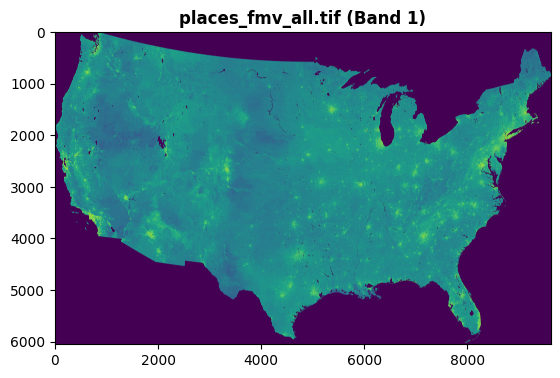

In [27]:
# Open the raster and print CRS, bounds, and meta info
import rasterio
from rasterio.plot import show

raster_path = "data/places_fmv_all.tif"

with rasterio.open(raster_path) as src:
    print('Raster shape (height, width):', src.shape)
    print('Raster count (bands):', src.count)
    print('Raster CRS:', src.crs)
    print('Raster bounds:', src.bounds)
    print('Raster transform:', src.transform)
    print('Raster dtype:', src.dtypes)
    arr = src.read(1)
    print('Raster min/max:', float(arr.min()), float(arr.max()))
    show(arr, title='places_fmv_all.tif (Band 1)')

In [29]:
# Efficient raster extraction: For each plant, average raster values within 3 miles (4828m), with logging for progress
import numpy as np
import rasterio
from shapely.geometry import Point
from pyproj import Transformer

raster_path = "data/places_fmv_all.tif"

transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)
mean_values = []

with rasterio.open(raster_path) as src:
    arr = src.read(1)
    affine = src.transform
    nodata = src.nodata
    height, width = src.shape
    for i, (lat, lon) in enumerate(zip(df_matched['Plant latitude'], df_matched['Plant longitude'])):
        if i % 500 == 0:
            print(f"Processing plant {i}/{len(df_matched)}...")
        if pd.isna(lat) or pd.isna(lon):
            mean_values.append(np.nan)
            continue
        # Project plant location to raster crs
        x, y = transformer.transform(lon, lat)
        pt = Point(x, y)
        # Buffer by 4828 m (3 mi)
        buf = pt.buffer(4828)
        # Bounding box in raster indices
        minx, miny, maxx, maxy = buf.bounds
        # Convert bounds to raster indices
        row_start, col_start = ~affine * (minx, maxy)
        row_stop, col_stop = ~affine * (maxx, miny)
        row_start = max(int(np.floor(row_start)), 0)
        col_start = max(int(np.floor(col_start)), 0)
        row_stop = min(int(np.ceil(row_stop)), height-1)
        col_stop = min(int(np.ceil(col_stop)), width-1)
        # Subarray extraction
        if row_stop <= row_start or col_stop <= col_start:
            mean_values.append(np.nan)
            continue
        subarr = arr[row_start:row_stop+1, col_start:col_stop+1]
        subaffine = affine * rasterio.Affine.translation(col_start, row_start)
        # Create mask inside buffer
        rows, cols = np.indices(subarr.shape)
        xs = subaffine.c + cols * subaffine.a
        ys = subaffine.f + rows * subaffine.e
        flat_xs = xs.ravel()
        flat_ys = ys.ravel()
        points = np.column_stack((flat_xs, flat_ys))
        mask = np.array([buf.contains(Point(xy[0], xy[1])) for xy in points]).reshape(subarr.shape)
        mask = mask & np.isfinite(subarr)
        pixvals = subarr[mask]
        mean = float(np.nanmean(pixvals)) if len(pixvals) > 0 else np.nan
        mean_values.append(mean)

# Update dataframe
print("Extraction complete! Example means:")
print(mean_values[:5])
df_matched['mean_property_value_3mi'] = mean_values
print(df_matched[['Plant name', 'mean_property_value_3mi']].head())

Processing plant 0/12612...
Processing plant 500/12612...
Processing plant 1000/12612...
Processing plant 1500/12612...
Processing plant 2000/12612...
Processing plant 2500/12612...
Processing plant 3000/12612...
Processing plant 3500/12612...
Processing plant 4000/12612...
Processing plant 4500/12612...
Processing plant 5000/12612...
Processing plant 5500/12612...
Processing plant 6000/12612...
Processing plant 6500/12612...
Processing plant 7000/12612...
Processing plant 7500/12612...
Processing plant 8000/12612...
Processing plant 8500/12612...
Processing plant 9000/12612...
Processing plant 9500/12612...
Processing plant 10000/12612...
Processing plant 10500/12612...
Processing plant 11000/12612...
Processing plant 11500/12612...
Processing plant 12000/12612...
Processing plant 12500/12612...
Extraction complete! Example means:
[nan, nan, nan, nan, nan]
            Plant name  mean_property_value_3mi
0             Alakanuk                      NaN
1  Allison Creek Hydro            

In [30]:
# Verify coordinate transform and raster indexing for property extraction
from shapely.geometry import Point
from pyproj import Transformer
import rasterio

raster_path = "data/places_fmv_all.tif"

transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)

# Print a sample of projected coordinates and their raster indices
with rasterio.open(raster_path) as src:
    affine = src.transform
    height, width = src.shape
    print(f"Raster shape: {height} x {width}, bounds: {src.bounds}")
    # Try the first 5 plants in the lower 48 states (not Alaska/Hawaii)
    for idx, row in df_matched.head(100).iterrows():
        lon, lat = row['Plant longitude'], row['Plant latitude']
        if not pd.isna(lat) and not pd.isna(lon):
            x, y = transformer.transform(lon, lat)
            print(f"Plant {row['Plant name']} proj x, y: {x:.0f}, {y:.0f}")
            col, row_ = ~affine * (x, y)
            col, row_ = int(np.round(col)), int(np.round(row_))
            print(f"Raster indices: col {col}, row {row_}")
            # Check if in raster bounds
            in_bounds = (0 <= row_ < height) and (0 <= col < width)
            print(f"  In bounds: {in_bounds}")
            if in_bounds:
                val = src.read(1)[row_, col]
                print(f"  Raster value at plant pixel: {val}")
            else:
                print("  Plant is outside raster bounds.")
            # Stop after 5 valid location checks
            if idx >= 5:
                break


Raster shape: 6054 x 9618, bounds: BoundingBox(left=-2357205.0, bottom=268005.0, right=2259435.0, top=3173925.0)
Plant Alakanuk proj x, y: -3709614, 5720011
Raster indices: col -2818, row -5304
  In bounds: False
  Plant is outside raster bounds.
Plant Allison Creek Hydro proj x, y: -2914630, 4952748
Raster indices: col -1161, row -3706
  In bounds: False
  Plant is outside raster bounds.
Plant Ambler proj x, y: -3151571, 5790948
Raster indices: col -1655, row -5452
  In bounds: False
  Plant is outside raster bounds.
Plant Angoon proj x, y: -2421319, 4296875
Raster indices: col -134, row -2339
  In bounds: False
  Plant is outside raster bounds.
Plant Aniak proj x, y: -3544313, 5441995
Raster indices: col -2473, row -4725
  In bounds: False
  Plant is outside raster bounds.
Plant Annex Creek proj x, y: -2359617, 4362249
Raster indices: col -5, row -2476
  In bounds: False
  Plant is outside raster bounds.


In [31]:
# Find a plant in the continental US likely to be within raster bounds
import rasterio
from pyproj import Transformer

raster_path = "data/places_fmv_all.tif"
transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)

with rasterio.open(raster_path) as src:
    affine = src.transform
    height, width = src.shape
    arr = src.read(1)
    print(f"Raster bounds: {src.bounds}, shape: {height}x{width}")
    # Try with some plants in the lower 48 states
    sample_us = df_matched[
        (df_matched['Plant latitude'] < 50) & (df_matched['Plant latitude'] > 24) &
        (df_matched['Plant longitude'] > -125) & (df_matched['Plant longitude'] < -65)
    ].head(3)
    for i, row in sample_us.iterrows():
        lon, lat = row['Plant longitude'], row['Plant latitude']
        x, y = transformer.transform(lon, lat)
        print(f"Plant: {row['Plant name']} Lon,Lat=({lon},{lat}) => x={x:.0f}, y={y:.0f}")
        col, row_ = ~affine * (x, y)
        col, row_ = int(np.round(col)), int(np.round(row_))
        print(f"Raster indices: col={col}, row={row_}, in bounds: {(0 <= row_ < height) and (0 <= col < width)}")
        if (0 <= row_ < height) and (0 <= col < width):
            val = arr[row_, col]
            print(f"Raster value at plant pixel: {val}")
        else:
            print("No valid raster data at this plant location.")

Raster bounds: BoundingBox(left=-2357205.0, bottom=268005.0, right=2259435.0, top=3173925.0), shape: 6054x9618
Plant: ABC Coke Lon,Lat=(-86.779866,33.582793) => x=848619, y=1209562
Raster indices: col=6679, row=4092, in bounds: True
Raster value at plant pixel: 12.671708106994629
Plant: AMEA Sylacauga Plant Lon,Lat=(-86.2825,33.1661) => x=898991, y=1167836
Raster indices: col=6784, row=4179, in bounds: True
Raster value at plant pixel: 10.658212661743164
Plant: ANAD Solar Array Lon,Lat=(-85.969481,33.626728) => x=922424, y=1221995
Raster indices: col=6833, row=4067, in bounds: True
Raster value at plant pixel: 10.933770179748535


In [35]:
# Show mean_property_value_3mi for plants within raster bounds (not NaN), including metadata
in_bounds_plants = df_matched[(df_matched['mean_property_value_3mi'].notna())]
display(in_bounds_plants[['Plant name', 'Plant state abbreviation', 'Plant latitude', 'Plant longitude', 'mean_property_value_3mi']].head(20))
print(f"Total power plants with non-NaN mean property value: {in_bounds_plants.shape[0]}")

,Plant name,Plant state abbreviation,Plant latitude,Plant longitude,mean_property_value_3mi
2303,Greater Sandhill I,CO,37.685467,-105.890900,8.507645
2446,SunE Alamosa,CO,37.690304,-105.880501,8.510422
3569,Amalgamated Sugar Twin Falls,ID,42.532800,-114.432800,10.479037
3579,Bennett Creek Windfarm LLC - Mountain Home,ID,43.053600,-115.480300,8.622033
3580,Bennett Mountain Power Project,ID,43.147153,-115.666637,11.420364
3584,"Black Mesa Solar, LLC",ID,42.907410,-115.181539,8.645050
3585,Blind Canyon Hydro,ID,42.699840,-114.822603,9.285366
3593,Camp Reed,ID,42.811944,-115.048889,8.846057
3597,Cassia Wind,ID,42.844400,-115.036900,8.848420
3600,Clear Lake,ID,42.667010,-114.780120,9.536643


Total power plants with non-NaN mean property value: 79


# in contiguous US bounds: 12329 / 12612
CA    1727
NY     897
NC     895
TX     824
MN     759
MA     624
NJ     401
IL     344
IA     287
CO     280
MI     273
FL     269
OR     267
GA     250
PA     248
WI     234
VA     219
IN     204
SC     203
OH     194
MD     189
ME     175
KS     167
CT     162
AZ     157
AK     152
WA     142
ID     140
NM     140
MO     130
Name: Plant state abbreviation, dtype: int64


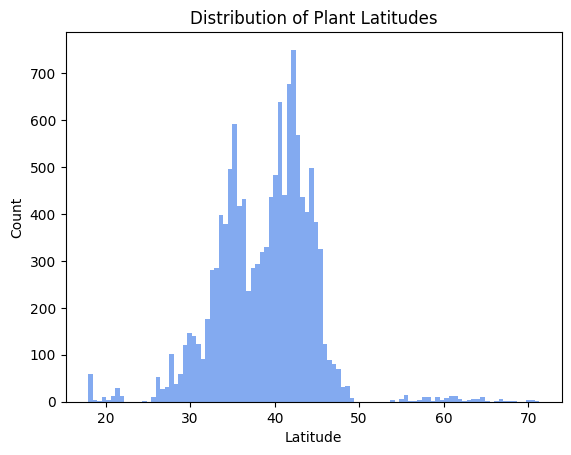

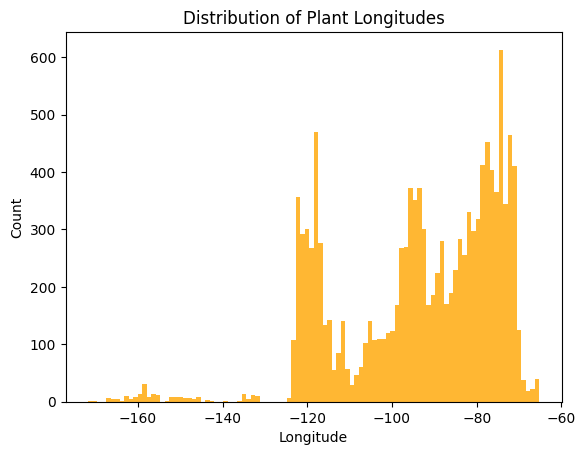

Plants with non-NaN mean property value: 79


,Plant name,Plant state abbreviation,Plant latitude,Plant longitude
0,Alakanuk,AK,62.683300,-164.654400
1,Allison Creek Hydro,AK,61.084444,-146.353333
2,Ambler,AK,67.087980,-157.856719
3,Angoon,AK,57.499166,-134.586140
4,Aniak,AK,61.580678,-159.535643
5,Annex Creek,AK,58.317600,-134.101000
6,Auke Bay,AK,58.387500,-134.644600
7,Aurora Energy LLC Chena,AK,64.847743,-147.735063
8,Barrow,AK,71.292000,-156.778600
9,Battery Energy Storage System,AK,64.816700,-147.725000


In [36]:
# Analyze why most plants do not have in-bounds mean property value
import matplotlib.pyplot as plt

def is_continental_us(lat, lon):
    # bounds are rough, for lower 48
    return (
        lat is not None and lon is not None and
        (24 <= lat <= 50) and (-125 <= lon <= -66)
    )

df_matched['in_lower_48'] = [is_continental_us(lat, lon) for lat, lon in zip(df_matched['Plant latitude'], df_matched['Plant longitude'])]
count_in_us = df_matched['in_lower_48'].sum()
print(f"# in contiguous US bounds: {count_in_us} / {len(df_matched)}")

# Distribution by state (top 30)
state_counts = df_matched['Plant state abbreviation'].value_counts().head(30)
print(state_counts)

# Plot histogram of latitudes/longitudes to visualize coverage
df_matched['Plant latitude'] = pd.to_numeric(df_matched['Plant latitude'], errors='coerce')
df_matched['Plant longitude'] = pd.to_numeric(df_matched['Plant longitude'], errors='coerce')
plt.hist(df_matched['Plant latitude'], bins=100, color='cornflowerblue', alpha=0.8)
plt.title('Distribution of Plant Latitudes')
plt.xlabel('Latitude'); plt.ylabel('Count')
plt.show()
plt.hist(df_matched['Plant longitude'], bins=100, color='orange', alpha=0.8)
plt.title('Distribution of Plant Longitudes')
plt.xlabel('Longitude'); plt.ylabel('Count')
plt.show()

# Plants with valid (non-NA) property value
print(f"Plants with non-NaN mean property value: {in_bounds_plants.shape[0]}")

# Show a few samples for plants out of bounds
display(df_matched.loc[~df_matched['in_lower_48'], ['Plant name','Plant state abbreviation','Plant latitude','Plant longitude']].head(15))

In [37]:
# Debug raster value extraction for California plants
from pyproj import Transformer
import rasterio

raster_path = "data/places_fmv_all.tif"
transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)

with rasterio.open(raster_path) as src:
    affine = src.transform
    height, width = src.shape
    arr = src.read(1)
    # Filter to first 10 California plants
    ca_plants = df_matched[df_matched['Plant state abbreviation'] == 'CA'].head(10)
    for i, row in ca_plants.iterrows():
        lon, lat = row['Plant longitude'], row['Plant latitude']
        x, y = transformer.transform(lon, lat)
        print(f"CA Plant: {row['Plant name']} lon/lat=({lon},{lat}) [1m=>[0m EPSG:5070 x={x:.0f}, y={y:.0f}")
        col, row_ = ~affine * (x, y)
        col, row_ = int(np.round(col)), int(np.round(row_))
        print(f"Raster indices: col={col}, row={row_}, in bounds: {(0 <= row_ < height) and (0 <= col < width)}")
        if (0 <= row_ < height) and (0 <= col < width):
            val = arr[row_, col]
            print(f"  Raster value at plant pixel: {val}")
        else:
            print("  Plant is outside raster bounds.")

CA Plant: 20333 Normandie PV, LLC lon/lat=(-118.30019,33.84614) => EPSG:5070 x=-2030074, y=1437067
Raster indices: col=682, row=3618, in bounds: True
  Raster value at plant pixel: 14.9252290725708
CA Plant: 20701 Plummer PV, LLC lon/lat=(-118.58517,34.243444) => EPSG:5070 x=-2045076, y=1486350
Raster indices: col=650, row=3516, in bounds: True
  Raster value at plant pixel: 15.299760818481445
CA Plant: 2081 Terzian Solar Project lon/lat=(-119.415833,36.67) => EPSG:5070 x=-2052546, y=1767940
Raster indices: col=635, row=2929, in bounds: True
  Raster value at plant pixel: 10.145295143127441
CA Plant: 2097 Helton Solar Project lon/lat=(-120.506944,37.352222) => EPSG:5070 x=-2126613, y=1865958
Raster indices: col=480, row=2725, in bounds: True
  Raster value at plant pixel: 11.83891773223877
CA Plant: 2127 Harris Solar Project lon/lat=(-121.669722,39.291667) => EPSG:5070 x=-2167102, y=2102074
Raster indices: col=396, row=2233, in bounds: True
  Raster value at plant pixel: 11.32413387298

In [38]:
import numpy as np
from pyproj import Transformer
from shapely.geometry import Point
import rasterio

# 3 mile buffer in meters
dist_m = 4828

raster_path = "data/places_fmv_all.tif"
transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)

with rasterio.open(raster_path) as src:
    arr = src.read(1)
    affine = src.transform
    nodata = src.nodata if src.nodata is not None else np.nan
    height, width = src.shape
    pixel_size = affine.a  # should be 480m in proj units
    win_rad = int(np.ceil(dist_m / pixel_size))
    mean_vals = []
    for i, row in df_matched.iterrows():
        lat, lon = row['Plant latitude'], row['Plant longitude']
        if pd.isna(lat) or pd.isna(lon):
            mean_vals.append(np.nan)
            continue
        # Project plant location
        x, y = transformer.transform(lon, lat)
        # Convert to raster indices
        col_center, row_center = ~affine * (x, y)
        row_center, col_center = int(np.round(row_center)), int(np.round(col_center))
        # Window bounds
        row_start = max(0, row_center - win_rad)
        row_stop  = min(height, row_center + win_rad + 1)
        col_start = max(0, col_center - win_rad)
        col_stop  = min(width, col_center + win_rad + 1)
        # If the window is clearly outside bounds, skip
        if row_start >= height or row_stop <= 0 or col_start >= width or col_stop <= 0:
            mean_vals.append(np.nan)
            continue
        subarr = arr[row_start:row_stop, col_start:col_stop]
        # Compute spatial coordinates of raster window centers
        rows, cols = np.indices(subarr.shape)
        abs_rows = row_start + rows
        abs_cols = col_start + cols
        xs, ys = affine * (abs_cols, abs_rows)
        # Distance from center in meters
        dists = np.sqrt((xs - x) ** 2 + (ys - y) ** 2)
        # Mask for inside buffer
        mask = (dists <= dist_m) & np.isfinite(subarr) & (subarr != nodata)
        pixvals = subarr[mask]
        mean = float(np.nanmean(pixvals)) if pixvals.size > 0 else np.nan
        mean_vals.append(mean)
        if i % 500 == 0:
            print(f"Processed {i} / {len(df_matched)}...")

df_matched['mean_property_value_3mi'] = mean_vals
print(df_matched[['Plant name','Plant state abbreviation','Plant latitude','Plant longitude','mean_property_value_3mi']].head(20))
print(f"Total power plants with non-NaN mean property value: {(~pd.isna(df_matched['mean_property_value_3mi'])).sum()}")

Processed 500 / 12612...
Processed 1000 / 12612...
Processed 1500 / 12612...
Processed 2000 / 12612...
Processed 2500 / 12612...
Processed 3000 / 12612...
Processed 3500 / 12612...
Processed 4000 / 12612...
Processed 4500 / 12612...
Processed 5000 / 12612...
Processed 5500 / 12612...
Processed 6000 / 12612...
Processed 6500 / 12612...
Processed 7000 / 12612...
Processed 7500 / 12612...
Processed 8000 / 12612...
Processed 8500 / 12612...
Processed 9000 / 12612...
Processed 9500 / 12612...
Processed 10000 / 12612...
Processed 10500 / 12612...
Processed 11000 / 12612...
Processed 11500 / 12612...
Processed 12000 / 12612...
Processed 12500 / 12612...
                       Plant name Plant state abbreviation  Plant latitude  \
0                        Alakanuk                       AK       62.683300   
1             Allison Creek Hydro                       AK       61.084444   
2                          Ambler                       AK       67.087980   
3                          Angoon

In [39]:
# Print diagnostics for the raster extraction logic on a sample of lower-48 plants
import random
from pyproj import Transformer
import rasterio

raster_path = "data/places_fmv_all.tif"
transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)
exp_dist_m = 4828

with rasterio.open(raster_path) as src:
    arr = src.read(1)
    affine = src.transform
    nodata = src.nodata if src.nodata is not None else np.nan
    height, width = src.shape
    pixel_size = affine.a
    win_rad = int(np.ceil(exp_dist_m / pixel_size))

    sample = df_matched[(df_matched['in_lower_48'])].sample(10, random_state=42)
    print(f"Raster shape: {height}x{width}, bounds: {src.bounds}")
    for i, row in sample.iterrows():
        plant_id = row.get('DOE/EIA ORIS plant or facility code', i)
        lat, lon = row['Plant latitude'], row['Plant longitude']
        if pd.isna(lat) or pd.isna(lon):
            print(f"Plant {plant_id}: Missing coordinates.")
            continue
        x, y = transformer.transform(lon, lat)
        col_center, row_center = ~affine * (x, y)
        row_center, col_center = int(np.round(row_center)), int(np.round(col_center))
        print(f"Plant {plant_id}: proj (x, y)=({x:.1f}, {y:.1f}) => raster (row, col)=({row_center},{col_center})")
        # Buffer window
        row_start = max(0, row_center - win_rad)
        row_stop = min(height, row_center + win_rad + 1)
        col_start = max(0, col_center - win_rad)
        col_stop = min(width, col_center + win_rad + 1)
        print(f"\twindow rows {row_start}-{row_stop}, cols {col_start}-{col_stop}")
        if row_stop <= row_start or col_stop <= col_start:
            print("\tOut of raster bounds for this window.")
            continue
        subarr = arr[row_start:row_stop, col_start:col_stop]
        print(f"\tsubarr shape: {subarr.shape}")
        rows, cols = np.indices(subarr.shape)
        abs_rows = row_start + rows
        abs_cols = col_start + cols
        xs, ys = affine * (abs_cols, abs_rows)
        dists = np.sqrt((xs - x) ** 2 + (ys - y) ** 2)
        mask = (dists <= exp_dist_m) & np.isfinite(subarr) & (subarr != nodata)
        pix_count = mask.sum()
        print(f"\t# pixels in mask: {pix_count} (should be >0)")
        if pix_count > 0:
            print(f"\tmean value in buffer: {np.nanmean(subarr[mask]):.4f}")
            print(f"\traw values in buffer: {subarr[mask][:5]}")
        else:
            print(f"\tNo valid raster pixels in mask!")
        print(f"\traw center pixel value: {arr[row_center, col_center] if 0 <= row_center < height and 0 <= col_center < width else None}")
        print()

Raster shape: 6054x9618, bounds: BoundingBox(left=-2357205.0, bottom=268005.0, right=2259435.0, top=3173925.0)
Plant 55259: proj (x, y)=(703442.3, 2105990.5) => raster (row, col)=(2225,6376)
	window rows 2214-2237, cols 6365-6388
	subarr shape: (23, 23)
	# pixels in mask: 229 (should be >0)
	mean value in buffer: 11.5960
	raw values in buffer: [11.473387 11.141591 10.994384 11.648639 11.497548]
	raw center pixel value: 12.185354232788086

Plant 56569: proj (x, y)=(-1793237.1, 1314623.2) => raster (row, col)=(3874,1175)
	window rows 3863-3886, cols 1164-1187
	subarr shape: (23, 23)
	# pixels in mask: 318 (should be >0)
	mean value in buffer: 8.5455
	raw values in buffer: [8.516367 8.479585 9.029004 8.543348 7.730792]
	raw center pixel value: 8.519190788269043

Plant 10362: proj (x, y)=(63304.7, 1408986.8) => raster (row, col)=(3677,5043)
	window rows 3666-3689, cols 5032-5055
	subarr shape: (23, 23)
	# pixels in mask: 315 (should be >0)
	mean value in buffer: 10.0134
	raw values in buff

In [40]:
import numpy as np
from pyproj import Transformer
from shapely.geometry import Point
import rasterio

# Set up buffer size and raster info
dist_m = 4828
raster_path = "data/places_fmv_all.tif"
transformer = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)

with rasterio.open(raster_path) as src:
    arr = src.read(1)
    affine = src.transform
    nodata = src.nodata if src.nodata is not None else np.nan
    height, width = src.shape
    pixel_size = affine.a  # should be 480m in proj units
    win_rad = int(np.ceil(dist_m / pixel_size))
    mean_vals = []
    # Just continental US (likely in bounds)
    for i, row in df_matched.iterrows():
        lat, lon = row['Plant latitude'], row['Plant longitude']
        if pd.isna(lat) or pd.isna(lon) or not (24 <= lat <= 50 and -125 <= lon <= -66):
            mean_vals.append(np.nan)
            continue
        # Project plant location
        x, y = transformer.transform(lon, lat)
        # Convert to raster indices
        col_center, row_center = ~affine * (x, y)
        row_center, col_center = int(np.round(row_center)), int(np.round(col_center))
        # Window bounds
        row_start = max(0, row_center - win_rad)
        row_stop  = min(height, row_center + win_rad + 1)
        col_start = max(0, col_center - win_rad)
        col_stop  = min(width, col_center + win_rad + 1)
        # If window is outside, skip
        if row_start >= height or row_stop <= 0 or col_start >= width or col_stop <= 0:
            mean_vals.append(np.nan)
            continue
        subarr = arr[row_start:row_stop, col_start:col_stop]
        # Compute spatial coordinates of raster window centers
        rows, cols = np.indices(subarr.shape)
        abs_rows = row_start + rows
        abs_cols = col_start + cols
        xs, ys = affine * (abs_cols, abs_rows)
        # Distance from center in meters
        dists = np.sqrt((xs - x) ** 2 + (ys - y) ** 2)
        # Mask for inside buffer
        mask = (dists <= dist_m) & np.isfinite(subarr) & (subarr != nodata)
        pixvals = subarr[mask]
        mean = float(np.nanmean(pixvals)) if pixvals.size > 0 else np.nan
        mean_vals.append(mean)
        if i % 1000 == 0:
            print(f"Processed {i} / {len(df_matched)} -- example mean: {mean}")
df_matched['mean_property_value_3mi'] = mean_vals
print("\n--- Extraction summary:")
valid = (~df_matched['mean_property_value_3mi'].isna()).sum()
tot = df_matched.shape[0]
print(f"Total power plants with non-NaN mean property value: {valid} / {tot}")
print("Sample (lower 48) with valid value:")
display(df_matched.loc[(df_matched['mean_property_value_3mi'].notna()) & df_matched['in_lower_48'], ['Plant name','Plant state abbreviation','Plant latitude','Plant longitude','mean_property_value_3mi']].head(10))

Processed 1000 / 12612 -- example mean: 8.831670761108398
Processed 2000 / 12612 -- example mean: 11.142404556274414
Processed 3000 / 12612 -- example mean: 9.481731414794922
Processed 4000 / 12612 -- example mean: 10.159466743469238
Processed 5000 / 12612 -- example mean: 9.227883338928223
Processed 6000 / 12612 -- example mean: 9.493961334228516
Processed 7000 / 12612 -- example mean: 10.145254135131836
Processed 8000 / 12612 -- example mean: 10.840566635131836
Processed 9000 / 12612 -- example mean: 10.93742847442627
Processed 10000 / 12612 -- example mean: 10.639253616333008
Processed 11000 / 12612 -- example mean: 9.978087425231934
Processed 12000 / 12612 -- example mean: 8.691161155700684

--- Extraction summary:
Total power plants with non-NaN mean property value: 12327 / 12612
Sample (lower 48) with valid value:


,Plant name,Plant state abbreviation,Plant latitude,Plant longitude,mean_property_value_3mi
152,ABC Coke,AL,33.582793,-86.779866,11.434388
153,AMEA Sylacauga Plant,AL,33.166100,-86.282500,10.238027
154,ANAD Solar Array,AL,33.626728,-85.969481,10.489552
155,Alabama Pine Pulp,AL,31.582500,-87.488900,8.745241
156,Alabama River Pulp,AL,31.582500,-87.488900,8.745241
157,Albertville,AL,34.363389,-86.223889,9.396132
158,Bankhead Dam,AL,33.458665,-87.356823,8.084522
159,Barry,AL,31.006900,-88.010300,8.638985
160,Bartletts Ferry,AL,32.663000,-85.090800,10.181800
161,Bellefonte,AL,34.709200,-85.927800,9.126447


In [43]:
# Diagnose missing water grid CSV by listing files
import os
files = os.listdir()
print("Files in directory:", files)


Files in directory: ['Untitled spreadsheet - PLNT23.csv', 'usa_bus_features_2016.csv', 'siting_with_transmission.ipynb', 'TRANSMISSION_DATA_SUMMARY.md', '.DS_Store', 'LICENSE', 'requirements.txt', 'GRANULARITY_SUMMARY.md', 'README.md', 'DATAPLACE_README.md', 'meta_datacenter_top20_with_transmission_20251115_1751.csv', 'COMPREHENSIVE_MODEL_SUMMARY.md', 'app.py', 'STATE_CODE_EXPLANATION.md', 'algo.ipynb', '.git', 'all_substations_scored_20251115_1751.csv', 'MAP_VISUALIZATION_GUIDE.md', 'data']


In [44]:
# Load water grid CSV and inspect schema
water_csv = '/Users/aalibaali/Desktop/MIT E&C HACK 2025/climateEnergy25/data/synthetic_us_water_latlon_grid.csv'
df_water = pd.read_csv(water_csv)
print(f"Water grid shape: {df_water.shape}")
print(f"Water grid columns: {df_water.columns.tolist()}")
display(df_water.head())
# Show dtypes and summary
df_water.info()

Water grid shape: (780, 7)
Water grid columns: ['Latitude', 'Longitude', 'SurfaceWater_Availability', 'Groundwater_Availability', 'Water_Stress_Index', 'Potable_Population_Served', 'Potable_Capacity_MGD']


,Latitude,Longitude,SurfaceWater_Availability,Groundwater_Availability,Water_Stress_Index,Potable_Population_Served,Potable_Capacity_MGD
0,24.0,-125.00,0.73,4.79,0.70,132896,3.08
1,24.0,-122.97,0.54,0.92,0.39,487329,67.13
2,24.0,-120.93,1.45,0.60,0.26,86406,27.77
3,24.0,-118.90,3.14,1.20,0.72,58176,5.02
4,24.0,-116.86,0.50,4.39,0.87,368595,57.04


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 780 entries, 0 to 779
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Latitude                   780 non-null    float64
 1   Longitude                  780 non-null    float64
 2   SurfaceWater_Availability  780 non-null    float64
 3   Groundwater_Availability   780 non-null    float64
 4   Water_Stress_Index         780 non-null    float64
 5   Potable_Population_Served  780 non-null    int64  
 6   Potable_Capacity_MGD       780 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 42.8 KB


In [45]:
import numpy as np

def haversine_np(lat1, lon1, lat2, lon2):
    """Vectorized haversine for all pairs plant vs. water points (inputs in degrees)"""
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    dlat = lat2[:, None] - lat1[None, :]
    dlon = lon2[:, None] - lon1[None, :]
    a = np.sin(dlat/2)**2 + np.cos(lat1[None, :]) * np.cos(lat2[:, None]) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6371 * c  # Earth radius (km)

# Pre-extract
plant_lat = pd.to_numeric(df_matched['Plant latitude'], errors='coerce').values
plant_lon = pd.to_numeric(df_matched['Plant longitude'], errors='coerce').values
water_lat = df_water['Latitude'].values
water_lon = df_water['Longitude'].values
water_capacity = df_water['Potable_Capacity_MGD'].values

# For memory, we'll do 1 plant at a time (could vectorize for more speed/memory)
potable_weighted = []
for i in range(len(df_matched)):
    plat, plon = plant_lat[i], plant_lon[i]
    if np.isnan(plat) or np.isnan(plon):
        potable_weighted.append(np.nan)
        continue
    d_km = 6371 * np.arccos(
        np.sin(np.radians(plat))*np.sin(np.radians(water_lat)) +
        np.cos(np.radians(plat))*np.cos(np.radians(water_lat)) * np.cos(np.radians(plon-water_lon))
    )
    # Use inverse-distance squared weighting, with minimum distance of 1km to avoid div/inf
    weights = 1 / np.maximum(d_km, 1) ** 2
    val = np.sum(weights * water_capacity) / np.sum(weights)
    potable_weighted.append(val)
    if i % 1000 == 0:
        print(f"Processed {i}/{len(df_matched)} plants...")

df_matched['potable_capacity_mgd_weighted'] = potable_weighted
print("Sample of weighted potable water capacity assigned to power plants:")
display(df_matched[['Plant name','Plant latitude','Plant longitude','potable_capacity_mgd_weighted']].head(10))
print(f"Total plants with non-NaN weighted capacity: {(~pd.isna(df_matched['potable_capacity_mgd_weighted'])).sum()}")

Processed 0/12612 plants...
Processed 1000/12612 plants...
Processed 2000/12612 plants...
Processed 3000/12612 plants...
Processed 4000/12612 plants...
Processed 5000/12612 plants...
Processed 6000/12612 plants...
Processed 7000/12612 plants...
Processed 8000/12612 plants...
Processed 9000/12612 plants...
Processed 10000/12612 plants...
Processed 11000/12612 plants...
Processed 12000/12612 plants...
Sample of weighted potable water capacity assigned to power plants:


,Plant name,Plant latitude,Plant longitude,potable_capacity_mgd_weighted
0,Alakanuk,62.683300,-164.654400,49.141570
1,Allison Creek Hydro,61.084444,-146.353333,49.070407
2,Ambler,67.087980,-157.856719,49.254176
3,Angoon,57.499166,-134.586140,48.949825
4,Aniak,61.580678,-159.535643,49.097531
5,Annex Creek,58.317600,-134.101000,49.005103
6,Auke Bay,58.387500,-134.644600,49.002833
7,Aurora Energy LLC Chena,64.847743,-147.735063,49.207139
8,Barrow,71.292000,-156.778600,49.363363
9,Battery Energy Storage System,64.816700,-147.725000,49.206120


Total plants with non-NaN weighted capacity: 12612


In [46]:
# Save the full plant-node matched dataset (with property and water columns) to CSV
output_csv = 'power_plant_siting_master_data.csv'
df_matched.to_csv(output_csv, index=False)
print(f"Saved: {output_csv} ({df_matched.shape[0]} rows, {df_matched.shape[1]} columns)")

Saved: power_plant_siting_master_data.csv (12612 rows, 167 columns)
